# What distinguishes multi-victim femicides?

About a third of labeled cases involve more than one victim. This notebook trains an **XGBoost** classifier to tell
single-victim and multi-victim incidents apart from case attributes, then asks which attributes matter most.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from femicide import load_cases, load_population, top_categories, save

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11})
ACCENT = "#8E2C48"

from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier

In [2]:
cases = load_cases()

MULTI = {"SINGLE FEMICIDE": 0, "MULTIPLE FEMICIDE (SAME DAY or INCIDENT)": 1, "MULTIPLE FEMICIDE": 1,
         "SERIAL FEMICIDE": 1, "MULTIPLE & SERIAL FEMICIDE": 1}
labeled = cases[cases["MULTI & SERIAL VICTIMS"].isin(MULTI)].copy()
y = labeled["MULTI & SERIAL VICTIMS"].map(MULTI).astype(int)
print(f"{len(labeled):,} labeled cases, {y.mean():.0%} multi-victim")

1,854 labeled cases, 32% multi-victim


## Features

Categorical fields keep their most common values (the rest become *Other*), and missing values are kept as their
own category because whether something was recorded is itself informative.

In [3]:
FEATURES = {
    "Type of death": ("MURDER-SUICIDE / FAMILICIDE / SUSPECT DEATH", 8),
    "Relationship": ("RELATIONSHIP", 12),
    "Place of attack": ("PLACE OF ATTACK / DEATH", 10),
    "Cause of death": ("CAUSE / FEATURES OF DEATH", 8),
    "Victim race / ethnicity": ("HER RACE / ETH", 8),
}
cats = pd.DataFrame({name: top_categories(labeled[col], k) for name, (col, k) in FEATURES.items()})
X = pd.get_dummies(cats, prefix_sep=": ").astype(int)
X["Victim age"] = labeled["HER AGE"]
X["Suspect age"] = labeled["HIS AGE"]
X.shape

(1854, 53)

## Cross-validated performance

Five-fold stratified cross-validation, compared with always guessing the majority class (single victim).

In [4]:
def evaluate(X, y):
    model = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, eval_metric="logloss", random_state=42)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    pred = (proba >= 0.5).astype(int)
    scores = {"Accuracy": accuracy_score(y, pred), "Balanced accuracy": balanced_accuracy_score(y, pred),
              "ROC AUC": roc_auc_score(y, proba)}
    return model.fit(X, y), pred, scores

model, pred, scores = evaluate(X, y)
pd.Series({**scores, "Majority-class baseline": 1 - y.mean()}).round(3)

Accuracy                   0.810
Balanced accuracy          0.750
ROC AUC                    0.844
Majority-class baseline    0.680
dtype: float64

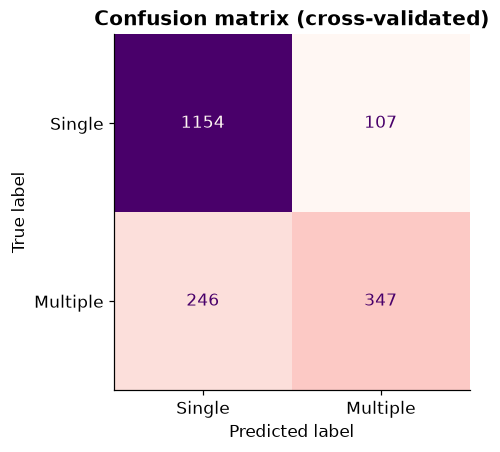

In [5]:
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Single", "Multiple"], cmap="RdPu",
                                        colorbar=False, ax=ax)
ax.set_title("Confusion matrix (cross-validated)")
save(fig, "confusion_matrix.png")

## Which attributes matter?

Importance is XGBoost's total gain, summed over each attribute's categories.

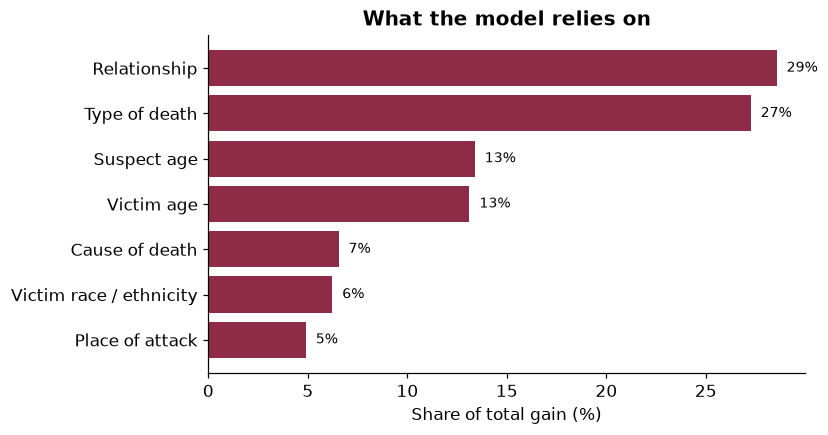

In [6]:
gain = pd.Series(model.get_booster().get_score(importance_type="total_gain"))
group = gain.index.str.split(": ").str[0]
by_feature = (gain.groupby(group).sum() / gain.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_feature.index, by_feature.values, color=ACCENT)
for i, v in enumerate(by_feature.values):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set(xlabel="Share of total gain (%)", title="What the model relies on")
save(fig, "feature_importance.png")

In [7]:
top = (gain / gain.sum() * 100).sort_values(ascending=False).head(10).round(1)
top.rename("Share of total gain (%)").to_frame()

,Share of total gain (%)
Type of death: Familicide-Suicide,14.0
Suspect age,13.4
Victim age,13.1
Type of death: Familicide,7.6
Relationship: Husband,6.0
Relationship: Boyfriend / Domestic Partner,5.8
Relationship: Unknown / Unreleased,4.6
Cause of death: Firearm,3.1
Relationship: Not recorded,2.8
Relationship: Ex-Boyfriend / Domestic Partner,2.6


## Without type of death

Familicide means killing family members, so it nearly defines a multi-victim case. Dropping type of death checks how
much the other attributes can predict on their own.

In [8]:
X_reduced = X.drop(columns=[c for c in X.columns if c.startswith("Type of death")])
_, _, reduced = evaluate(X_reduced, y)
pd.DataFrame({"All features": scores, "Without type of death": reduced}).round(3)

,All features,Without type of death
Accuracy,0.810,0.784
Balanced accuracy,0.750,0.722
ROC AUC,0.844,0.805


## Notes

- The multi-victim label is only filled in for some years (mostly 2019 and 2022–2024), so the model learns from
  that subset.
- These are associations in recorded cases, not causes.